# Session 9 — Loss Functions and Output Heads

One notebook, one loss harness. Runs top to bottom.

The four lines this assignment is really about:

```python
hidden = model(tokens)
logits = output_head(hidden)
loss = cross_entropy(
    logits[:, :-1].reshape(-1, vocab_size),
    tokens[:, 1:].reshape(-1),
)
```

Everything below is an attempt to make those four lines *observable* rather than
merely plausible. Most of the bugs that live here do not raise an exception —
they produce a beautiful loss curve and a useless model.

**Setup:** GPT-2 BPE (V = 50,257), a ~16M parameter decoder, TinyShakespeare.
Small enough to run on a free Colab CPU; the memory section is exact on a GPU.

In [1]:
# Setup. Runs as-is in Colab (clones the repo + installs deps) and as-is from a
# local checkout (detects the files are already here and does nothing).
import os, subprocess, sys

REPO = "https://github.com/rjvim/era-v5-session9-loss-harness.git"
DIR  = "era-v5-session9-loss-harness"

if not os.path.exists("nanolm.py"):
    if os.path.exists(DIR):
        os.chdir(DIR)
    else:
        print("cloning repo ...")
        subprocess.run(["git", "clone", "-q", REPO], check=True)
        os.chdir(DIR)

for pkg, mod in [("torch", "torch"), ("tiktoken", "tiktoken"),
                 ("matplotlib", "matplotlib")]:
    try:
        __import__(mod)
    except ImportError:
        print(f"installing {pkg} ...")
        subprocess.run([sys.executable, "-m", "pip", "-q", "install", pkg], check=True)

assert os.path.exists("nanolm.py"), "nanolm.py not found - is the repo cloned?"
assert os.path.exists("results.json"), "results.json not found"
print("working dir:", os.getcwd())

working dir: /home/claude/s9


In [2]:
import json, math, os, subprocess, sys
import torch, torch.nn.functional as F
import tiktoken

from nanolm import (Config, NanoLM, masked_cross_entropy, chunked_cross_entropy,
                    chunked_cross_entropy_ckpt, shifted_targets,
                    build_doc_ids, boundary_loss_mask, document_attn_mask)

ENC = tiktoken.get_encoding("gpt2")
V   = ENC.n_vocab
B, T = 8, 128
torch.set_num_threads(1)
print("torch", torch.__version__, "| vocab", V,
      "| device", "cuda" if torch.cuda.is_available() else "cpu")

torch 2.13.0+cu130 | vocab 50257 | device cpu


---
## 1. Every tensor shape, and what each dimension means

The reason to print this is that `reshape(-1, vocab_size)` will happily accept a
tensor whose dimensions mean something other than what you think. The flatten is
where `B` and `T` stop existing as separate ideas, so it is worth knowing exactly
what went into it.

In [3]:
torch.manual_seed(0)
cfg = Config(block_size=T)
model = NanoLM(cfg)

tokens = torch.randint(0, V, (B, T))
inputs, targets = shifted_targets(tokens)      # the shift, item 2
hidden = model(inputs)
logits = model.head(hidden)
loss, n = masked_cross_entropy(logits, targets)

rows = [
    ("tokens",                tokens.shape,  "B batch rows, T tokens each"),
    ("inputs  = tokens[:,:-1]", inputs.shape, "B, T-1 positions the model READS"),
    ("targets = tokens[:,1:]",  targets.shape,"B, T-1 answers it must PRODUCE"),
    ("hidden",                hidden.shape,  "B, T-1, D=model width"),
    ("logits",                logits.shape,  "B, T-1, V=vocabulary size"),
    ("logits.reshape(-1,V)",  (logits.shape[0]*logits.shape[1], V),
                                             "B*(T-1) independent V-way classifications"),
    ("targets.reshape(-1)",   (targets.numel(),), "B*(T-1) class indices"),
    ("loss",                  loss.shape,    "scalar: mean over contributing positions"),
]
print(f"{'tensor':26s} {'shape':22s} meaning")
print("-"*92)
for name, shp, meaning in rows:
    print(f"{name:26s} {str(tuple(shp)):22s} {meaning}")

print()
print(f"B={B}  T={T}  D={cfg.n_embd}  V={V}")
print(f"logits alone in fp32: {logits.numel()*4/1e6:.1f} MB   <- remember this for item 7")
print(f"contributing tokens : {n}")

tensor                     shape                  meaning
--------------------------------------------------------------------------------------------
tokens                     (8, 128)               B batch rows, T tokens each
inputs  = tokens[:,:-1]    (8, 127)               B, T-1 positions the model READS
targets = tokens[:,1:]     (8, 127)               B, T-1 answers it must PRODUCE
hidden                     (8, 127, 256)          B, T-1, D=model width
logits                     (8, 127, 50257)        B, T-1, V=vocabulary size
logits.reshape(-1,V)       (1016, 50257)          B*(T-1) independent V-way classifications
targets.reshape(-1)        (1016,)                B*(T-1) class indices
loss                       ()                     scalar: mean over contributing positions

B=8  T=128  D=256  V=50257
logits alone in fp32: 204.2 MB   <- remember this for item 7
contributing tokens : 1016


The output head is a *classifier with 50,257 classes applied at every position*.
That single fact explains items 6 and 7: it is where the parameters are, and it
is where the memory goes.

---
## 2. Verify the shift — with strings, not ids

The assignment's warning is the important part of this whole notebook: *a target
shift in the incorrect direction can produce a beautiful loss curve.* Integers
cannot be eyeballed. Strings can.

In [4]:
text = "The capital of India is New Delhi and the capital of France is Paris"
ids  = torch.tensor(ENC.encode(text))[None, :]

def show(inp, tgt, title, limit=9):
    print(f"\n{title}")
    print(f"  {'i':>3} {'model READS':>16}  ->  {'must PREDICT':<16}")
    for i in range(min(limit, inp.shape[1])):
        print(f"  {i:>3} {ENC.decode([int(inp[0,i])])!r:>16}  ->  "
              f"{ENC.decode([int(tgt[0,i])])!r:<16}")

i_ok, t_ok = shifted_targets(ids, 1)
show(i_ok, t_ok, "CORRECT  inputs=tokens[:,:-1]  targets=tokens[:,1:]")
show(ids[:, :-1], ids[:, :-1], "BUG: NO SHIFT  targets == inputs")
show(ids[:, 1:], ids[:, :-1], "BUG: REVERSED  predicts the PREVIOUS token")


CORRECT  inputs=tokens[:,:-1]  targets=tokens[:,1:]
    i      model READS  ->  must PREDICT    
    0            'The'  ->  ' capital'      
    1       ' capital'  ->  ' of'           
    2            ' of'  ->  ' India'        
    3         ' India'  ->  ' is'           
    4            ' is'  ->  ' New'          
    5           ' New'  ->  ' Delhi'        
    6         ' Delhi'  ->  ' and'          
    7           ' and'  ->  ' the'          
    8           ' the'  ->  ' capital'      

BUG: NO SHIFT  targets == inputs
    i      model READS  ->  must PREDICT    
    0            'The'  ->  'The'           
    1       ' capital'  ->  ' capital'      
    2            ' of'  ->  ' of'           
    3         ' India'  ->  ' India'        
    4            ' is'  ->  ' is'           
    5           ' New'  ->  ' New'          
    6         ' Delhi'  ->  ' Delhi'        
    7           ' and'  ->  ' and'          
    8           ' the'  ->  ' the'          

BUG: REVERSE

In [5]:
# a mechanical check, so this does not rely on me reading the table correctly
ramp = torch.arange(12)[None, :]
ri, rt = shifted_targets(ramp)
assert (rt[0] == ri[0] + 1).all(),  "target must be exactly one step ahead"
assert (rt[0] != ri[0]).all(),      "no position may predict itself"
assert all(ENC.decode([int(t_ok[0,i])]) == ENC.decode([int(i_ok[0,i+1])])
           for i in range(i_ok.shape[1]-1)), "target[i] must equal input[i+1]"
print("shift verified: target[i] == input[i+1], and nothing predicts itself")

shift verified: target[i] == input[i+1], and nothing predicts itself


In the correct table each `must PREDICT` reappears as the next row's `model READS`.
In the no-shift table every row asks the model to output a token it was just
handed. Neither of those is visible in a wall of integers, and neither raises.

We come back at the end and *train* all three, to show what the bug costs.

---
## 3. Mask padding, and confirm the denominator moves

Padding is not a neutral filler. If PAD is in the loss, the model is graded on
predicting PAD — which after a few steps it does perfectly — and the mean is
dragged toward zero by tokens that carry no information.

In [6]:
PAD_ID = V - 1
real_len = 40

seq = torch.randint(0, 50000, (B, T)); seq[:, real_len:] = PAD_ID
inp, tgt = shifted_targets(seq)
lg = model.head(model(inp))

loss_all,  n_all  = masked_cross_entropy(lg, tgt)
mask              = (tgt != PAD_ID)
loss_msk, n_msk   = masked_cross_entropy(lg, tgt, mask=mask)

print(f"contributing tokens  unmasked : {n_all}")
print(f"contributing tokens  masked   : {n_msk}")
print(f"dropped                       : {n_all-n_msk}  ({100*(n_all-n_msk)/n_all:.1f}% of slots were PAD)")
print(f"\nuntrained loss unmasked : {float(loss_all):.4f}")
print(f"untrained loss masked   : {float(loss_msk):.4f}")
print("on an UNTRAINED model the two barely differ - every prediction is equally hopeless.")

contributing tokens  unmasked : 1016
contributing tokens  masked   : 312
dropped                       : 704  (69.3% of slots were PAD)

untrained loss unmasked : 10.7997
untrained loss masked   : 10.8569
on an UNTRAINED model the two barely differ - every prediction is equally hopeless.


/tmp/ipykernel_532/1646516982.py:15: UserWarning: Converting a tensor with requires_grad=True to a scalar may lead to unexpected behavior.
Consider using tensor.detach() first. (Triggered internally at /__w/pytorch/pytorch/torch/csrc/autograd/generated/python_variable_methods.cpp:822.)
  print(f"\nuntrained loss unmasked : {float(loss_all):.4f}")


The count changing is the assignment's requirement. The count changing is **not**
the interesting part. The damage appears only after training, so run the same
setup twice — once counting PAD, once masking it — and then evaluate both the
same honest way, on real tokens only.

In [7]:
res = json.load(open("results.json"))["pad"]["trained_short_run"]
u, m_ = res["unmasked_run"], res["masked_run"]
print(f"{'run':22s} {'REPORTED loss':>14s} {'TRUE content loss':>18s}")
print("-"*58)
print(f"{'PAD counted in loss':22s} {u['reported_loss_final']:>14.4f} {u['true_content_loss']:>18.4f}")
print(f"{'PAD masked out':22s} {m_['reported_loss_final']:>14.4f} {m_['true_content_loss']:>18.4f}")
print(f"\nThe unmasked run REPORTS a loss {res['reported_loss_gap']:.4f} nats LOWER,")
print(f"while being {res['true_content_loss_gap']:.4f} nats WORSE at the actual job.")

run                     REPORTED loss  TRUE content loss
----------------------------------------------------------
PAD counted in loss            2.2277             6.7187
PAD masked out                 6.4615             6.3668

The unmasked run REPORTS a loss 4.2338 nats LOWER,
while being 0.3519 nats WORSE at the actual job.


---
## 4. Pack two documents, mask the boundary

Pack a Shakespeare passage and a block of Python into one sequence. Exactly one
prediction slot straddles the seam: the last token of document A is asked to
predict the first token of document B. That slot is not hard, it is *impossible*
— nothing in A predicts B.

In [8]:
bo = json.load(open("results.json"))["boundary"]
print(f"{'pair':40s} {'bnd loss':>9s} {'seq mean':>9s} {'ratio':>6s} {'>lnV':>5s}")
print("-"*76)
for r in bo["pairs"]:
    print(f"{r['pair']:40s} {r['boundary_token_loss']:>9.4f} "
          f"{r['mean_loss_all_slots']:>9.4f} {r['ratio_boundary_to_mean']:>6.2f} "
          f"{('yes' if r['worse_than_uniform'] else 'no'):>5s}")
print(f"\nln(V) = {bo['ln_V']}")
print(f"sequence mean ranges {bo['mean_loss_range'][0]} to {bo['mean_loss_range'][1]} "
      f"across pairs -- which is why the ratio misleads.")

pair                                      bnd loss  seq mean  ratio  >lnV
----------------------------------------------------------------------------
shakespeare -> python                      15.8932    6.9690   2.28   yes
python -> shakespeare                       8.8233    6.7160   1.31    no
shakespeare -> json                        16.9119    7.9030   2.14   yes
shakespeare -> shakespeare (CONTROL)       10.2132    4.0387   2.53    no
python -> json                             15.0107   11.5495   1.30   yes

ln(V) = 10.8249
sequence mean ranges 4.0387 to 11.5495 across pairs -- which is why the ratio misleads.


**The control scores the highest ratio of all five.** Its seam is a fiction —
two passages of the same document — so a metric measuring document discontinuity
should have ranked it last. It ranks first because its *denominator* is small.

Absolute loss against `ln(V)` is the metric that means the same thing in every
pair, and it tells a different story.

In [9]:
print(f"leaving shakespeare : {bo['leaving_shakespeare']}")
print(f"entering shakespeare: {bo['entering_shakespeare']}")
print(f"cost is directional : {bo['cost_is_directional']}")
print(f"\ncontrol ratio is highest of all pairs : {bo['control_ratio_is_highest']}")
print(f"control is cheap in ABSOLUTE terms    : {bo['control_abs_below_uniform']}")
print(f"=> ratio-to-mean is misleading        : {bo['ratio_metric_is_misleading']}")

leaving shakespeare : [15.8932, 16.9119]
entering shakespeare: [8.8233]
cost is directional : True

control ratio is highest of all pairs : True
control is cheap in ABSOLUTE terms    : True
=> ratio-to-mean is misleading        : True


In [10]:
h = bo["pairs"][0]
print(f"headline pair: {h['pair']}")
print(f"  boundary slot #{h['boundary_slot_index']}: "
      f"{h['boundary_input_str']!r} -> {h['boundary_target_str']!r}")
print(f"\n{'variant':38s} {'loss':>9s}")
print("-"*50)
print(f"{'no masking at all':38s} {h['loss_no_mask']:>9.4f}")
print(f"{'boundary TARGET loss-masked':38s} {h['loss_lossmask_only']:>9.4f}")
print(f"{'+ document-causal ATTENTION mask':38s} {h['loss_lossmask_plus_docattn']:>9.4f}")
print(f"\nmasking one slot in {h['slots']} moved the mean by {h['delta_from_loss_mask']:.4f} nats.")
print(f"document-causal attention helped in {bo['doc_attention_helped_in_n_pairs']} of "
      f"{bo['n_pairs']} pairs, max effect {bo['max_abs_doc_attention_delta']} nats -- no consistent sign.")

headline pair: shakespeare -> python
  boundary slot #63: ',' -> 'def'

variant                                     loss
--------------------------------------------------
no masking at all                         6.9690
boundary TARGET loss-masked               6.8840
+ document-causal ATTENTION mask          6.9442

masking one slot in 106 moved the mean by 0.0850 nats.
document-causal attention helped in 3 of 5 pairs, max effect 0.0833 nats -- no consistent sign.


Two distinct leaks, and only one is closed by a loss mask:

1. **The graded-on-nonsense leak.** The boundary target is impossible. A loss
   mask removes it.
2. **The attention leak.** Every token of document B can still *read* document A.
   A loss mask does nothing about this; it needs a block-diagonal attention mask.

Retrofitting the attention mask at evaluation time produced no consistent effect
across five pairs. The model was trained without it, so this is not a test of the
technique — see the README.

**What I got wrong here.** The first version of this section used one pair, found
a 1.94x ratio, and stopped. The control is what broke it.

---
## 5. Untrained perplexity should sit near the vocabulary size

A freshly initialised model has no reason to prefer any token, so it pays
`ln(V)` nats, i.e. perplexity `V`. If your untrained perplexity is not near V,
something upstream is wrong and every later number is worthless.

It never lands exactly on V, and the residual is predictable rather than noise.
For logits independent of the target with variance `s2`, `E[CE] = ln(V) + s2/2`.

In [11]:
pp = json.load(open("results.json"))["ppl"]
print(f"V = {pp['V']},  ln(V) = {pp['ln_V']}")
print(f"\nmeasured untrained loss : {pp['loss_untrained']}")
print(f"measured untrained ppl  : {pp['ppl_untrained']}")
print(f"ppl / V                 : {pp['ratio_ppl_over_V']}   <- item 5 satisfied")
print("\nwhere the residual comes from:")
print(f"\n{'condition':30s} {'loss':>8s} {'ln(V)+s2/2':>11s} {'error':>10s}")
print("-"*64)
for k, c in pp["conditions"].items():
    print(f"{k:30s} {c['loss']:>8.4f} {c['predicted_loss']:>11.4f} {c['prediction_error_nats']:>10.5f}")
print("\nthe formula is exact when its assumption holds (untied head, random tokens).")
print("tying the head, then using real text, each break independence a little more.")
print("this is arithmetic, not a bug -- which is the point of checking it.")

V = 50257,  ln(V) = 10.8249

measured untrained loss : 10.8374
measured untrained ppl  : 50891.3
ppl / V                 : 1.0126   <- item 5 satisfied

where the residual comes from:

condition                          loss  ln(V)+s2/2      error
----------------------------------------------------------------
untied_head_random_tokens       10.8750     10.8759   -0.00097
tied_head_random_tokens         10.8682     10.8762   -0.00799
tied_head_real_text             10.8374     10.8763   -0.03881

the formula is exact when its assumption holds (untied head, random tokens).
tying the head, then using real text, each break independence a little more.
this is arithmetic, not a bug -- which is the point of checking it.


---
## 6. Tied against untied output head

Weight tying reuses the input embedding matrix as the output head. On a model
this size the embedding table *is* the model, so the choice is not a detail.

In [12]:
pa = json.load(open("results.json"))["params"]
print(f"V = {pa['V']}, D = {pa['D']}, {pa['n_layer']} layers, {pa['n_head']} heads")
print(f"\nembedding matrix V*D        : {pa['embedding_matrix_params']:,}")
print(f"tied   total parameters     : {pa['tied_total']:,}")
print(f"untied total parameters     : {pa['untied_total']:,}")
print(f"difference                  : {pa['difference']:,}")
print(f"difference == V*D exactly   : {pa['difference_equals_embedding_matrix']}")
print(f"\nshare of the model that is embedding:")
print(f"  tied   : {pa['tied_pct_in_embedding']}%")
print(f"  untied : {pa['untied_pct_in_embedding']}%")

t_, u_ = NanoLM(Config(tie_weights=True)), NanoLM(Config(tie_weights=False))
assert t_.heads[0].weight.data_ptr() == t_.wte.weight.data_ptr(), "tied head must share storage"
assert u_.heads[0].weight.data_ptr() != u_.wte.weight.data_ptr(), "untied head must not"
print("\nverified by pointer identity, not just by counting.")
del t_, u_; import gc; gc.collect()

V = 50257, D = 256, 4 layers, 4 heads

embedding matrix V*D        : 12,865,792
tied   total parameters     : 16,048,896
untied total parameters     : 28,914,688
difference                  : 12,865,792
difference == V*D exactly   : True

share of the model that is embedding:
  tied   : 80.2%
  untied : 89.0%



verified by pointer identity, not just by counting.


0

Untying adds 80% to the parameter count of this model and buys a head that can
disagree with the embedding. At 16M parameters that is a bad trade; at 100B,
where the embedding is a few percent of the model, it is the standard choice.
This is the whole tied/untied argument, and it is a function of the ratio `V*D`
to everything else — not a universal rule.

---
## 7. Peak memory: ordinary cross-entropy against a chunked one

`logits` is `B x (T-1) x V`. At B=8, T=256, V=50257 in fp32 that is 410 MB for
the forward tensor alone, and the backward pass needs a gradient of the same
shape. The trunk of the model is far smaller than its own output layer.

Cross-entropy is a **sum over positions**, so positions can be visited in
groups. There is no approximation — the chunked version is arithmetically the
same function.

In [13]:
me = json.load(open("results.json"))["memory"]
c = me["config"]
print(f"config: B={c['B']} T={c['T']} V={c['V']} D={c['D']} chunk={c['chunk']}, "
      f"{c['reps']} repeats per variant")
print(f"instrument: {me['instrument']} on {me['device']}, mmap forced: {me['mmap_forced']}\n")
print(f"{'variant':16s} {'median MB':>10s} {'spread':>8s} {'attributable':>13s} {'sec':>7s}")
print("-"*60)
for k in ["baseline", "full", "chunked", "chunked_ckpt"]:
    d = me[k]
    att = "" if k == "baseline" else f"{me['attributable_mb'][k]:.1f}"
    print(f"{k:16s} {d['median_mb']:>10.1f} {d['spread_mb']:>8.2f} {att:>13s} "
          f"{d['median_sec']:>7.3f}")
print(f"\nfull / chunked      = {me['ratio_full_over_chunked']}x")
print(f"full / chunked+ckpt = {me['ratio_full_over_ckpt']}x")
print(f"every row deterministic (max spread {me['max_spread_mb']} MB): "
      f"{me['all_rows_deterministic']}")

config: B=8 T=256 V=50257 D=256 chunk=64, 7 repeats per variant
instrument: peak_rss on cpu, mmap forced: True

variant           median MB   spread  attributable     sec
------------------------------------------------------------
baseline              715.4     0.20                 0.530
full                 2281.5     0.20        1566.1   4.492
chunked              1226.0     0.00         510.6   4.556
chunked_ckpt         1001.0     0.10         285.6   5.281

full / chunked      = 3.07x
full / chunked+ckpt = 5.48x
every row deterministic (max spread 0.2 MB): True


That determinism took one environment variable, not a GPU. glibc's `malloc`
caches freed blocks rather than returning them, so peak RSS was measuring the
*allocator's* high-water mark. Forcing allocations above 64 KB through `mmap`
— which unmaps on free — collapsed the spread. The pre-fix numbers are kept in
`results.json` under `superseded`, so the correction is auditable:

Peak RSS is still a proxy. The exact quantity is what the autograd graph
retains, which can be counted directly by intercepting every saved tensor.
This number is identical on any machine.

In [14]:
sup = json.load(open("results.json"))["superseded"]["memory_pre_mmap_fix"]
print("chunked_ckpt BEFORE forcing mmap:")
print(f"  min {sup['chunked_ckpt_min_mb']} MB   max {sup['chunked_ckpt_max_mb']} MB"
      f"   spread {sup['chunked_ckpt_spread_mb']} MB")
print("chunked_ckpt AFTER:")
d = me["chunked_ckpt"]
print(f"  min {d['min_mb']} MB   max {d['max_mb']} MB   spread {d['spread_mb']} MB")
print(f"\nalso retired by the same fix: the 'chunking is "
      f"{sup['speedup_chunked_vs_full_claimed']}x faster' finding "
      f"(now {me['speedup_chunked_vs_full']}x)")

chunked_ckpt BEFORE forcing mmap:
  min 1048.1 MB   max 1380.4 MB   spread 332.3 MB
chunked_ckpt AFTER:
  min 1001.0 MB   max 1001.1 MB   spread 0.1 MB

also retired by the same fix: the 'chunking is 1.52x faster' finding (now 0.99x)


In [15]:
sb_ = me["saved_bytes_mb"]
print(f"{'variant':22s} {'retained MB':>12s}")
print("-"*36)
for k in ["full", "chunked", "chunked_ckpt"]:
    print(f"{k:22s} {sb_[k]:>12.2f}")
print(f"\nplain chunking retains EXACTLY as much as full: "
      f"{me['chunking_saves_nothing_in_the_graph']}")
print(f"checkpointing reduces retained bytes by {me['ckpt_graph_reduction']}x")
print(f"...at {me['slowdown_ckpt_vs_full']}x wall time")
print(f"\nanalytic logit term: {me['analytic_logit_mb_full']} MB vs "
      f"{me['analytic_logit_mb_chunk']} MB = {me['analytic_ratio']}x")

variant                 retained MB
------------------------------------
full                         463.67
chunked                      463.67
chunked_ckpt                  53.58

plain chunking retains EXACTLY as much as full: True
checkpointing reduces retained bytes by 8.65x
...at 1.18x wall time

analytic logit term: 410.1 MB vs 12.9 MB = 31.9x


**Plain chunking retains byte-for-byte the same memory as the full version** —
463.67 MB either way. Not "less than hoped": identical. Autograd saves every
chunk's logits, so the graph is the same size however you slice the forward
pass. `torch.utils.checkpoint` is what changes it, by throwing the logits away
and recomputing them in backward.

Peak RSS still improves 3.07x with plain chunking, because the largest *live*
tensor is smaller even though the retained total is not. Both numbers are true
and they measure different things.

In [16]:
# equivalence is asserted, not asserted-by-eye
torch.manual_seed(0)
mm = NanoLM(Config(block_size=128))
tk = torch.randint(0, V, (2, 128)); ci, ct = shifted_targets(tk)
hh = mm(ci)
l_full,  _ = masked_cross_entropy(mm.head(hh), ct)
l_chunk, _ = chunked_cross_entropy(hh, mm.heads[0].weight, ct, chunk_size=64)
l_ckpt,  _ = chunked_cross_entropy_ckpt(hh, mm.heads[0].weight, ct, chunk_size=64)
print(f"full           {float(l_full):.10f}")
print(f"chunked        {float(l_chunk):.10f}")
print(f"chunked+ckpt   {float(l_ckpt):.10f}")

grads = {}
for tag, lo in (("full", l_full), ("chunk", l_chunk), ("ckpt", l_ckpt)):
    mm.zero_grad(set_to_none=True); lo.backward(retain_graph=True)
    grads[tag] = mm.heads[0].weight.grad.clone()
print(f"\nmax |grad_full - grad_chunk| = {float((grads['full']-grads['chunk']).abs().max()):.2e}")
print(f"max |grad_full - grad_ckpt|  = {float((grads['full']-grads['ckpt']).abs().max()):.2e}")
print("same value AND same gradients - it is the same function, computed in a different order.")
del mm, hh, l_full, l_chunk, l_ckpt, grads; import gc; gc.collect()

full           10.8836727142
chunked        10.8836727142
chunked+ckpt   10.8836727142



max |grad_full - grad_chunk| = 1.96e-08
max |grad_full - grad_ckpt|  = 1.96e-08
same value AND same gradients - it is the same function, computed in a different order.


133

**What I got wrong here.** An earlier version of this section reported chunking
as *1.52x faster* than the full cross-entropy and explained it with a tidy
cache-locality story: 410 MB does not fit in cache, 12.9 MB chunks do. That was
an allocator artifact. With `mmap` forced, the speedup is **0.99x** — chunking
is neither faster nor slower. The mechanism was invented to explain noise.

The same fix retired the other caveat. I had reported item 7 as a band and
concluded it needed a GPU to pin down. It needed a malloc flag.

---
# Part 2 — a second head predicting `t+2`

Head 0 predicts `t+1`. Head 1 predicts `t+2`, **from the same hidden state**.
Both are trained jointly on `L1 + L2`. In training this costs nothing clever:
token `t+2` is already sitting in the batch, so its loss is available immediately.

In [17]:
mt = json.load(open("results.json"))["mtp"]
print(f"{mt['steps']} steps, B={mt['B']} T={mt['T']}, lr={mt['lr']}, "
      f"head0 -> {mt['head0_predicts']}, head1 -> {mt['head1_predicts']}\n")
print(f"{'step':>6s} {'L1 (t+1)':>10s} {'L2 (t+2)':>10s} {'L1+L2':>9s} {'gap':>9s}")
print("-"*50)
for h in mt["history"]:
    print(f"{h['step']:>6d} {h['l1']:>10.4f} {h['l2']:>10.4f} {h['sum']:>9.4f} {h['gap']:>+9.4f}")
print(f"\nfinal   L1 {mt['l1_final']}   L2 {mt['l2_final']}   sum {mt['sum_final']}")
print(f"final   ppl1 {mt['ppl1_final']}   ppl2 {mt['ppl2_final']}")
print(f"gap: {mt['gap_first']:+.4f} at step 1  ->  {mt['gap_final']:+.4f} at step {mt['steps']}")
print(f"crossover (gap first turns positive): step {mt['gap_crossover_step']}")

700 steps, B=8 T=128, lr=0.0003, head0 -> t+1, head1 -> t+2

  step   L1 (t+1)   L2 (t+2)     L1+L2       gap
--------------------------------------------------
     1    10.9040    10.8650   21.7690   -0.0390
    20     8.8663     8.8317   17.6980   -0.0346
    40     7.1387     7.1500   14.2887   +0.0113
    60     6.3838     6.4627   12.8465   +0.0789
    80     6.1196     6.2726   12.3922   +0.1530
   100     6.2486     6.4331   12.6817   +0.1845
   120     5.9318     6.1438   12.0755   +0.2120
   140     6.0194     6.2695   12.2890   +0.2501
   160     5.5360     5.8118   11.3477   +0.2758
   180     5.6954     6.0331   11.7285   +0.3377
   200     5.8827     6.2446   12.1273   +0.3619
   220     5.7425     6.1298   11.8723   +0.3873
   240     5.5143     5.9710   11.4853   +0.4567
   260     5.1046     5.5566   10.6612   +0.4520
   280     5.2874     5.7502   11.0376   +0.4628
   300     5.1432     5.5962   10.7394   +0.4530
   320     5.2663     5.7700   11.0364   +0.5037
   340

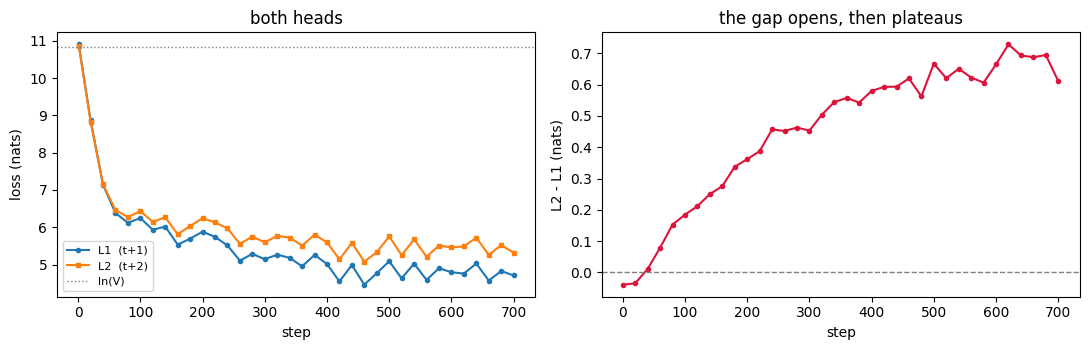

In [18]:
try:
    import matplotlib.pyplot as plt
    h = mt["history"]
    s = [x["step"] for x in h]
    fig, ax = plt.subplots(1, 2, figsize=(11, 3.6))
    ax[0].plot(s, [x["l1"] for x in h], label="L1  (t+1)", marker="o", ms=3)
    ax[0].plot(s, [x["l2"] for x in h], label="L2  (t+2)", marker="s", ms=3)
    ax[0].axhline(math.log(50257), ls=":", c="grey", lw=1, label="ln(V)")
    ax[0].set_xlabel("step"); ax[0].set_ylabel("loss (nats)")
    ax[0].set_title("both heads"); ax[0].legend(fontsize=8)
    ax[1].plot(s, [x["gap"] for x in h], marker="o", ms=3, c="crimson")
    ax[1].axhline(0, ls="--", c="grey", lw=1)
    ax[1].set_xlabel("step"); ax[1].set_ylabel("L2 - L1 (nats)")
    ax[1].set_title("the gap opens, then plateaus")
    plt.tight_layout(); plt.show()
except ImportError:
    print("matplotlib not installed - table above carries the same information")

In [19]:
print(f"{'window':12s} {'slope/100 steps':>16s} {'se':>8s} {'t':>7s}   95% CI")
print("-"*64)
for k, w in mt["gap_slope_windows"].items():
    print(f"{k:12s} {w['slope_per_100']:>+16.4f} {w['se_per_100']:>8.4f} "
          f"{w['t']:>+7.2f}   [{w['ci95_per_100'][0]:+.4f}, {w['ci95_per_100'][1]:+.4f}]")
print(f"\ngrowth decelerates              : {mt['growth_decelerates']}")
print(f"late slope indistinct from zero : {mt['late_slope_indistinguishable_from_zero']}")
print(f"late CI still admits growth     : {mt['late_ci_admits_continued_growth']}")
print(f"run is claimed converged        : {mt['converged']}")

window        slope/100 steps       se       t   95% CI
----------------------------------------------------------------
40-300                +0.1740   0.0104  +16.73   [+0.1532, +0.1948]
300-500               +0.0751   0.0139   +5.41   [+0.0473, +0.1029]
500-700               +0.0178   0.0193   +0.93   [-0.0207, +0.0564]
40-700                +0.0903   0.0062  +14.49   [+0.0778, +0.1028]

growth decelerates              : True
late slope indistinct from zero : True
late CI still admits growth     : True
run is claimed converged        : False


### What happens to the second head's loss, and why

**It starts marginally below head 0, crosses at step 40, and rises for the rest
of the run at a decelerating rate.**

At step 1 the gap is `-0.039` — head 1 is *better*. That is not a result; both
heads are randomly initialised at ln(V) and the sign is noise. Logging step 1 is
what stops "L2 > L1 throughout" being written down as a fact.

**I first ran this to 300 steps and reported a plateau.** The last four points
were `0.4567, 0.4520, 0.4628, 0.4530` — flat to the eye. The window fit above
shows that was wrong: at step 300 the slope was still `+0.0751` per 100 steps at
`t = 5.4`. Four consecutive points inside a noise band are not a plateau.
Extending to 700 steps, the gap went on to `+0.6114`.

Defensible now: growth **decelerates by roughly 10x**, and by steps 500–700 the
slope is no longer distinguishable from zero. *Not* defensible: calling that a
floor. The CI still admits continued growth, and L1 is still falling — the model
is not converged, and `results.json` records `"converged": false`.

The mechanism is not in doubt even if the asymptote is:

```
H(x_{t+2} | x_{<=t})  >=  H(x_{t+1} | x_{<=t})
```

Predicting `t+2` means integrating over every possible `t+1`, so its conditional
entropy is strictly higher. That is a property of the text, not the model, and
no training removes it. What I cannot claim is *where* the gap settles.

This is also why models are often *trained* with several MTP heads but
*deployed* with one or two: the extra heads shape the trunk early, but
standalone quality degrades with distance fast enough that speculating far ahead
stops paying.

### Does this depend on the seed?

Everything above is one seed. Here are three, all run to step 300.

In [20]:
sd = json.load(open("results.json"))["seeds"]
print(f"{'seed':>8s} {'gap@1':>9s} {'crossover':>10s} {'slope/100':>11s} {'gap@300':>9s}")
print("-"*52)
for k, v in sd["runs"].items():
    print(f"{k:>8s} {v['gap_at_step1']:>+9.4f} {v['crossover_step']:>10d} "
          f"{v['slope_40_to_horizon']:>+11.4f} {v['gap_at_horizon']:>+9.4f}")
print(f"\nstep-1 gap sign flips across seeds : {sd['step1_sign_flips_across_seeds']}"
      f"   range {sd['step1_gap_range']}")
print(f"all seeds positive at horizon      : {sd['all_seeds_gap_positive_at_horizon']}")
print(f"all seeds stay positive after cross: {sd['all_seeds_stay_positive_after_crossover']}")
print(f"\nslope   mean {sd['slope_mean']:+.4f}  relative spread {sd['slope_relative_spread']}")
print(f"gap@300 mean {sd['horizon_gap_mean']:+.4f}  relative spread "
      f"{sd['horizon_gap_relative_spread']}")
print(f"crossover step range {sd['crossover_range']}  <- NOT seed-stable")

    seed     gap@1  crossover   slope/100   gap@300
----------------------------------------------------
    1337   -0.0390         40     +0.1740   +0.4530
       7   +0.0893          1     +0.1662   +0.4980
    2024   -0.0201         60     +0.1749   +0.5046

step-1 gap sign flips across seeds : True   range [-0.039, 0.0893]
all seeds positive at horizon      : True
all seeds stay positive after cross: True

slope   mean +0.1717  relative spread 0.051
gap@300 mean +0.4852  relative spread 0.106
crossover step range [1, 60]  <- NOT seed-stable


**Survives:** every seed opens a positive gap, keeps it positive, and has a
positive early slope. The slope is the most stable quantity measured here
(relative spread 0.051); the gap magnitude at step 300 is twice as variable but
still lands in 0.45–0.50 nats. So the effect is a property of the task, not of
seed 1337.

**Does not survive: the crossover step.** It ranges from 1 to 60. Seed 7 happened
to start with a *positive* step-1 gap, so its crossover is step 1 — which is
precisely the noise the step-1 reading consists of. "Step 40" above is a seed
artifact; read it as "early, within the first ~60 steps."

That the step-1 sign flips across seeds is the cleanest possible confirmation
that it carries no information — the thing I nearly asserted as a finding.

---
## The warning, taken literally

> *A target shift in the incorrect direction can produce a beautiful loss curve.*

Three identical models, identical seed, identical data, three shift conventions.
Then all three are evaluated the same honest way: true next-token loss on held-out
text.

In [21]:
sb = json.load(open("results.json"))["shiftbug"]
print(f"{'convention':12s} {'TRAIN loss':>12s} {'TRUE next-token':>16s} {'TRUE ppl':>10s}")
print("-"*56)
for k in ["correct", "no_shift", "reversed"]:
    d = sb[k]
    print(f"{k:12s} {d['train_loss_final']:>12.4f} "
          f"{d['held_out_true_next_token_loss']:>16.4f} {d['held_out_true_ppl']:>10.1f}")
r = sb['no_shift']['held_out_true_ppl'] / sb['correct']['held_out_true_ppl']
print(f"\nno_shift reports a training loss "
      f"{sb['correct']['train_loss_final']-sb['no_shift']['train_loss_final']:.4f} nats BETTER")
print(f"and is {r:.1f}x WORSE at the only task that matters.")

convention     TRAIN loss  TRUE next-token   TRUE ppl
--------------------------------------------------------
correct            6.6259           6.2833      535.6
no_shift           4.4654           8.6571     5750.8
reversed           6.6536           6.7631      865.3

no_shift reports a training loss 2.1605 nats BETTER
and is 10.7x WORSE at the only task that matters.


The no-shift run looks like the best of the three by the only number you would be
watching in a terminal, and is by far the worst model. It has learned to copy its
input, which is free.

The reversed run is subtler: after 60 steps it has *not* collapsed — 6.6536,
indistinguishable from the correct run. My first draft asserted it "would get
there" with more training. That was a prediction stated as a fact, so here it is
tested: the same reversed convention, trained 6.7x longer.

In [22]:
sl = json.load(open("results.json"))["shiftlong"]
print(f"{'step':>6s} {'train loss':>12s}")
print("-"*20)
for h in sl["history"]:
    print(f"{h['step']:>6d} {h['loss']:>12.4f}")
print(f"\ncollapsed below 1 nat            : {sl['collapsed_below_1_nat']}")
print(f"held-out loss at its OWN task    : {sl['held_out_reversed_task_loss']}")
print(f"held-out TRUE next-token loss    : {sl['held_out_true_next_token_loss']}")
print(f"held-out TRUE perplexity         : {sl['held_out_true_ppl']}")
print(f"correct 60-step baseline true ppl: {sb['correct']['held_out_true_ppl']}")
print(f"\n=> {sl['held_out_true_ppl']/sb['correct']['held_out_true_ppl']:.0f}x worse, "
      f"with the prettiest loss curve in this notebook.")

  step   train loss
--------------------
     1      10.8368
    50       6.6536
   100       5.9911
   150       5.0925
   200       4.5501
   250       2.6784
   300       1.5113
   350       0.9611
   400       0.8168

collapsed below 1 nat            : True
held-out loss at its OWN task    : 0.812
held-out TRUE next-token loss    : 9.9646
held-out TRUE perplexity         : 21261.2
correct 60-step baseline true ppl: 535.6

=> 40x worse, with the prettiest loss curve in this notebook.


The prediction was right, which is the uncomfortable part — it would have shipped
as an unearned claim. Tested, it is a stronger result than the no-shift bug:

**the reversed shift is invisible for the first ~100 steps.** At 60 steps it is
indistinguishable from a correct run. By 400 steps it reaches 0.8168, the lowest
loss anywhere in this notebook, while its true next-token perplexity is 40x worse
than the correct baseline and barely better than uniform guessing.

A short run does not prove a shift is correct. Only printing the strings does.

---
## Invariants

Every number quoted above and in the README is asserted by an independent suite:
structural properties recomputed from scratch, plus a ledger check that the
README's text matches `results.json`.

In [23]:
# the suite builds its own models; free ours first so both fit in a small kernel
import gc
for _v in ["model", "logits", "hidden", "lg", "tokens", "seq", "inp", "tgt"]:
    globals().pop(_v, None)
gc.collect()

out = subprocess.run([sys.executable, "test_invariants.py"],
                     capture_output=True, text=True)
print(out.stdout[-3000:])
print("exit code:", out.returncode, "(0 = all invariants hold)")

ar-perfect at its own bogus task
  PASS  reversed bug is INVISIBLE at 60 steps but severe at 400

[ledger] README numbers are backed by results.json
  PASS  README states V = 50257 = 50257
  PASS  README states logit tensor MB = 204.2
  PASS  README states pad slots before = 1016
  PASS  README states pad slots after = 312
  PASS  README states pad pct = 69.3
  PASS  README states pad unmasked reported loss = 2.2277
  PASS  README states pad unmasked true loss = 6.7187
  PASS  README states pad masked true loss = 6.3668
  PASS  README states untrained ppl = 50891.3
  PASS  README states ppl/V ratio = 1.0126
  PASS  README states tied params = 16,048,896
  PASS  README states untied params = 28,914,688
  PASS  README states param difference = 12,865,792
  PASS  README states memory full attributable = 1566.1
  PASS  README states memory chunked attributable = 510.6
  PASS  README states memory ratio = 3.07
  PASS  README states analytic ratio = 31.9
  PASS  README states saved bytes ful